# 256 px vs 768 px final model: source-by-source comparison

Two checkpoints of the final concept-bottleneck run, both scored on the full CoralNet test split (144 held-out sources)
from the per-point dumps of `scripts/dump_point_predictions.py`:

| key | checkpoint | input |
|---|---|---|
| **256** | `cbm_final_res256/model_step300000` | 256 px, 300k updates |
| **768** | `cbm_final_res768/model_step50000` | 768 px fine-tune of the 256 model, 50k updates |

Both use the same concept table (`class_to_concepts_final.csv`) and concept list, so ground truth is identical point by
point (checked below); every difference is the model's.

**Questions.** Beyond pooled / mean / median numbers: is 768 a little better everywhere, much better in a few
sources, or better in some and worse in others? Which sources are good for both, bad for both?

**How a source is classified (per rank).**
- *Level* — the mean of the two models' accuracy in the source, against the quartiles of that mean over sources:
  `weak for both` (≤ Q1), `middle`, `strong for both` (≥ Q3). Relative, like the bottom-quarter rule of
  `Weak_Source_Diagnosis.ipynb`.
- *Difference* — Δ = acc(768) − acc(256), with a 95% bootstrap CI that resamples **images** within the source (points
  in an image are not independent). `768 better` if the CI is above 0 and Δ ≥ `MIN_DELTA`; `256 better` mirrored;
  otherwise `no clear difference`. `MIN_DELTA` stops very large sources from counting a 0.5-point gain as a difference.

**Live hard coral** (sections 5–6). A point is *live hard coral* if `live` = True and order = Scleractinia. It is *not*
live hard coral if `live` = False (this includes dead coral) or any annotated rank rules Scleractinia out (kingdom ≠
animalia, phylum ≠ cnidaria, class ∉ {hexacorallia, anthozoa}, order ≠ scleractinia). Remaining points (e.g. `live`
not given, or a live animal without an order) are left out of the detection metrics. Two views:
1. **Per-rank accuracy on live hard coral points only** (ground truth restricted to live hard coral) — recall-type: how
   well the taxonomy of corals is predicted, blind to false alarms.
2. **Live-hard-coral detection on all points** — predicted positive if the order head says Scleractinia *and*
   p(`live`) > 0.5; precision, recall and F1 per source.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy.stats import spearmanr, wilcoxon

REPO = Path("../..").resolve()
sys.path.insert(0, str(REPO))

DUMPS = {
    "256": REPO / "results_tmp/cbm_final_res256_step300000/test",
    "768": Path(os.environ.get("CMP_768_DUMP", REPO / "results_tmp/cbm_final_res768_step50000/test")),
}
A, B = "256", "768"
RANKS = ["kingdom", "phylum", "class", "order", "family", "genus"]
MIN_N = 200        # min points labelled at a rank for a source to enter that rank's comparison
MIN_N_LIVE = 100   # same, for the live-hard-coral views
MIN_DELTA = 0.02   # min |Δ| (with CI excluding 0) to call a source different
N_BOOT = 1000
SEED = 0
LIVE_THR = 0.5
HARD_CORAL_ANCESTORS = {"kingdom": {"animalia"}, "phylum": {"cnidaria"}, "class": {"hexacorallia", "anthozoa"},
                        "order": {"scleractinia"}}
WEAK_SOURCES_256 = None  # filled from section 1 (bottom quarter of 256 kingdom accuracy, as in Weak_Source_Diagnosis)

# Categorical slots 1-3 of the palette used in the other result_eda notebooks; grey = no clear difference.
C_B, C_A, C_3, C_NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#a8a7a2"
DIFF_COLOR = {f"{B} better": C_B, "no clear difference": C_NEUTRAL, f"{A} better": C_A}
LEVELS = ["weak for both", "middle", "strong for both"]
INK = "#0b0b0b"; INK2 = "#52514e"; GRID = "#e4e3df"; SURFACE = "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

GT_COLS = ["point_id", "source_id", "image_id", "label_idx", "source_label_name", "gt__live",
           *[f"gt_{r}" for r in RANKS]]
PRED_COLS = ["p__live", *[f"pred_{r}" for r in RANKS]]

def load(path):
    return pd.read_parquet(path / "points.parquet", columns=GT_COLS + PRED_COLS)

raw = {k: load(p) for k, p in DUMPS.items()}
for k, p in DUMPS.items():
    print(f"{k}: {len(raw[k]):,} points  ({p})")

# Same points, same ground truth.
a, b = raw[A], raw[B]
assert len(a) == len(b) and (a.point_id.values == b.point_id.values).all(), "dumps are not row-aligned"
same_gt = {c: bool((a[c].astype(str).values == b[c].astype(str).values).all()) for c in ["gt__live", *[f"gt_{r}" for r in RANKS]]}
print("identical ground truth per column:", same_gt)
assert all(same_gt.values()) or os.environ.get("CMP_ALLOW_GT_DIFF"), "ground truth differs between dumps; the comparison would mix label and model changes"

256: 1,511,187 points  (/data/vision/beery/scratch/viktordo/mermaid-segmentation/results_tmp/cbm_final_res256_step300000/test)
768: 1,511,187 points  (/data/vision/beery/scratch/viktordo/mermaid-segmentation/results_tmp/cbm_final_res768_step50000/test)


identical ground truth per column: {'gt__live': True, 'gt_kingdom': True, 'gt_phylum': True, 'gt_class': True, 'gt_order': True, 'gt_family': True, 'gt_genus': True}


In [2]:
# One frame: ground truth once, correctness and live-hard-coral prediction per model.
df = a[["source_id", "image_id", "source_label_name", "gt__live", *[f"gt_{r}" for r in RANKS]]].copy()
for r in RANKS:
    g = df[f"gt_{r}"].astype(str).where(df[f"gt_{r}"].notna())
    for k in (A, B):
        df[f"ok_{r}_{k}"] = (g == raw[k][f"pred_{r}"].astype(str)) & g.notna()

# Live hard coral ground truth: 1 = yes, 0 = no, NaN = undetermined.
pos = (df.gt__live == 2) & (df.gt_order.astype(str) == "scleractinia")
neg = df.gt__live == 1
for r, ok in HARD_CORAL_ANCESTORS.items():
    neg |= df[f"gt_{r}"].notna() & ~df[f"gt_{r}"].astype(str).isin(ok)
df["lhc"] = np.where(pos, 1.0, np.where(neg, 0.0, np.nan))
for k in (A, B):
    df[f"lhc_pred_{k}"] = (raw[k]["pred_order"].astype(str) == "scleractinia") & (raw[k]["p__live"] > LIVE_THR)
del raw, a, b
print(f"live hard coral: {int(pos.sum()):,} points; not: {int((df.lhc == 0).sum()):,}; undetermined: {int(df.lhc.isna().sum()):,}")
print(f"sources with ≥ {MIN_N_LIVE} live hard coral points: {(df[pos].source_id.value_counts() >= MIN_N_LIVE).sum()} of {df.source_id.nunique()}")

live hard coral: 169,153 points; not: 1,232,005; undetermined: 110,029
sources with ≥ 100 live hard coral points: 82 of 144


In [3]:
def image_counts(mask: pd.Series, cols: list[str]) -> pd.DataFrame:
    """Per (source, image): number of points under `mask` and the sum of each boolean column."""
    x = df.loc[mask, ["source_id", "image_id", *cols]]
    g = x.groupby(["source_id", "image_id"], observed=True)
    return g[cols].sum().assign(n=g.size()).reset_index()

def boot_ci(W: np.ndarray, stat) -> tuple[float, float]:
    vals = stat(W)
    return tuple(np.nanpercentile(vals, [2.5, 97.5]))

def paired_table(mask: pd.Series, rank: str | None = None, min_n: int = MIN_N, seed: int = SEED) -> pd.DataFrame:
    """Per source: accuracy of both models on the points in `mask` (labelled at `rank`), Δ and its image-bootstrap CI."""
    m = mask & df[f"gt_{rank}"].notna()
    cols = [f"ok_{rank}_{A}", f"ok_{rank}_{B}"]
    ic = image_counts(m, cols)
    rng = np.random.default_rng(seed)
    rows = []
    for s, g in ic.groupby("source_id"):
        n = g.n.to_numpy(float)
        if n.sum() < min_n:
            continue
        ca, cb = g[cols[0]].to_numpy(float), g[cols[1]].to_numpy(float)
        W = rng.multinomial(len(g), np.full(len(g), 1 / len(g)), size=N_BOOT).astype(float)
        wn = W @ n
        lo, hi = boot_ci(W, lambda W: (W @ cb - W @ ca) / wn)
        rows.append({"source_id": s, "n": int(n.sum()), "images": len(g), f"acc_{A}": ca.sum() / n.sum(),
                     f"acc_{B}": cb.sum() / n.sum(), "lo": lo, "hi": hi})
    t = pd.DataFrame(rows).set_index("source_id")
    return classify(t)

def classify(t: pd.DataFrame, a_col: str = f"acc_{A}", b_col: str = f"acc_{B}") -> pd.DataFrame:
    t = t.copy()
    t["delta"] = t[b_col] - t[a_col]
    t["mean"] = (t[a_col] + t[b_col]) / 2
    q1, q3 = t["mean"].quantile([0.25, 0.75])
    t["level"] = np.select([t["mean"] <= q1, t["mean"] >= q3], [LEVELS[0], LEVELS[2]], LEVELS[1])
    t["diff"] = np.select([(t.lo > 0) & (t.delta >= MIN_DELTA), (t.hi < 0) & (t.delta <= -MIN_DELTA)],
                          [f"{B} better", f"{A} better"], "no clear difference")
    t.attrs["q"] = (q1, q3)
    return t

def headline(t: pd.DataFrame, pooled: tuple[float, float], a_col=f"acc_{A}", b_col=f"acc_{B}") -> dict:
    """Pooled, mean and median over sources, paired tests and the source counts per difference category."""
    d = t[b_col] - t[a_col]
    p = wilcoxon(t[b_col], t[a_col]).pvalue if len(t) > 5 and (d != 0).any() else np.nan
    vc = t["diff"].value_counts()
    return {"sources": len(t), f"pooled {A}": pooled[0], f"pooled {B}": pooled[1],
            f"mean {A}": t[a_col].mean(), f"mean {B}": t[b_col].mean(),
            f"median {A}": t[a_col].median(), f"median {B}": t[b_col].median(),
            "median Δ": d.median(), "IQR Δ": f"{d.quantile(.25):+.3f} … {d.quantile(.75):+.3f}",
            "Wilcoxon p": p, f"n {B} better": int(vc.get(f"{B} better", 0)),
            "n no clear diff": int(vc.get("no clear difference", 0)), f"n {A} better": int(vc.get(f"{A} better", 0))}

def pooled_acc(mask: pd.Series, rank: str) -> tuple[float, float]:
    m = mask & df[f"gt_{rank}"].notna()
    return tuple(df.loc[m, f"ok_{rank}_{k}"].mean() for k in (A, B))

In [4]:
def plot_pairs(tables: dict, title: str, a_col=f"acc_{A}", b_col=f"acc_{B}", label="accuracy", ncols=3):
    """Per panel: one dot per source, 256 on x and 768 on y; colour = difference category, area ~ √points."""
    n = len(tables); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 4.3 * nrows), squeeze=False)
    for ax, (name, t) in zip(axes.flat, tables.items()):
        lo = max(0, min(t[a_col].min(), t[b_col].min()) - 0.03)
        ax.plot([lo, 1], [lo, 1], color=INK2, lw=1, ls="--", zorder=1)
        q1, q3 = t.attrs["q"]
        for q in (q1, q3):  # level boundaries: lines where mean(acc) = q
            ax.plot([lo, 1], [2 * q - lo, 2 * q - 1], color=GRID, lw=1.2, zorder=0)
        for cat, col in DIFF_COLOR.items():
            x = t[t["diff"] == cat]
            ax.scatter(x[a_col], x[b_col], s=8 + 1.2 * np.sqrt(x.n), color=col, alpha=0.85,
                       edgecolor=SURFACE, linewidth=1, zorder=3)
        ax.set_xlim(lo, 1.01); ax.set_ylim(lo, 1.01); ax.set_aspect("equal")
        vc = t["diff"].value_counts()
        ax.set_title(f"{name}  ({len(t)} sources)\n{B} better {vc.get(f'{B} better', 0)} · same {vc.get('no clear difference', 0)} · "
                     f"{A} better {vc.get(f'{A} better', 0)}", fontsize=9.5)
        ax.set_xlabel(f"{label}, {A}"); ax.set_ylabel(f"{label}, {B}")
    for ax in axes.flat[n:]:
        ax.axis("off")
    handles = [Line2D([], [], marker="o", ls="", color=c, label=k, markersize=8) for k, c in DIFF_COLOR.items()]
    handles += [Line2D([], [], color=INK2, ls="--", label="equal"), Line2D([], [], color=GRID, lw=1.5, label="level boundaries (Q1, Q3 of mean)")]
    fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(title, y=1.0); fig.tight_layout(rect=(0, 0.03, 1, 1))
    return fig

def plot_delta_vs_level(tables: dict, title: str, ncols=3, label="accuracy"):
    """Δ against the source's mean accuracy (Bland–Altman): does 768 help weak sources more?"""
    n = len(tables); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.4 * nrows), squeeze=False)
    for ax, (name, t) in zip(axes.flat, tables.items()):
        ax.axhline(0, color=INK2, lw=1, ls="--")
        ax.axhline(t.delta.median(), color=C_B, lw=1.2, label="median Δ")
        for cat, col in DIFF_COLOR.items():
            x = t[t["diff"] == cat]
            ax.errorbar(x["mean"], x.delta, yerr=[x.delta - x.lo, x.hi - x.delta], fmt="o", ms=4, color=col,
                        ecolor=col, elinewidth=0.8, alpha=0.85)
        rho = spearmanr(t["mean"], t.delta).statistic
        ax.set_title(f"{name}  (Spearman ρ = {rho:+.2f})", fontsize=9.5)
        ax.set_xlabel(f"mean {label} of the two models"); ax.set_ylabel(f"Δ {label} ({B} − {A})")
    for ax in axes.flat[n:]:
        ax.axis("off")
    fig.suptitle(title, y=1.0); fig.tight_layout()
    return fig

def crosstab(tables: dict) -> pd.DataFrame:
    rows = []
    for name, t in tables.items():
        ct = pd.crosstab(t.level, t["diff"]).reindex(index=LEVELS, columns=list(DIFF_COLOR), fill_value=0)
        rows.append(ct.assign(rank=name).set_index("rank", append=True).swaplevel())
    return pd.concat(rows)

## 1. Headline numbers, all annotated points

Per rank: pooled accuracy (all points of all sources), the mean and median of per-source accuracy, the median and
interquartile range of the per-source Δ, a paired Wilcoxon test over sources, and how many sources fall in each
difference category. Sources with fewer than `MIN_N` labelled points at a rank are left out of that rank.

In [5]:
ALL = pd.Series(True, index=df.index)
T = {r: paired_table(ALL, r) for r in RANKS}
H = pd.DataFrame({r: headline(T[r], pooled_acc(ALL, r)) for r in RANKS}).T
WEAK_SOURCES_256 = set(T["kingdom"][T["kingdom"][f"acc_{A}"] <= T["kingdom"][f"acc_{A}"].quantile(0.25)].index)
H.style.format(precision=3, na_rep="–")

,sources,pooled 256,pooled 768,mean 256,mean 768,median 256,median 768,median Δ,IQR Δ,Wilcoxon p,n 768 better,n no clear diff,n 256 better
kingdom,139,0.717,0.738,0.762,0.781,0.789,0.822,0.016,+0.003 … +0.032,0.000,54,78,7
phylum,139,0.705,0.726,0.756,0.776,0.794,0.825,0.017,+0.004 … +0.030,0.000,52,80,7
class,138,0.714,0.735,0.766,0.786,0.811,0.840,0.016,+0.002 … +0.033,0.000,51,80,7
order,137,0.729,0.749,0.800,0.820,0.831,0.854,0.013,+0.002 … +0.032,0.000,49,81,7
family,133,0.782,0.812,0.821,0.850,0.858,0.892,0.021,+0.002 … +0.054,0.000,61,68,4
genus,133,0.776,0.804,0.809,0.838,0.853,0.892,0.017,+0.002 … +0.047,0.000,58,70,5


## 2. Each source, both models

One dot per source: 256 accuracy on x, 768 on y. Above the dashed diagonal = 768 better. The two light lines are the
level boundaries (bottom-left of the lower line = weak for both, top-right of the upper line = strong for both).
Colour = difference category (CI excludes 0 and |Δ| ≥ `MIN_DELTA`); dot area ~ √points.

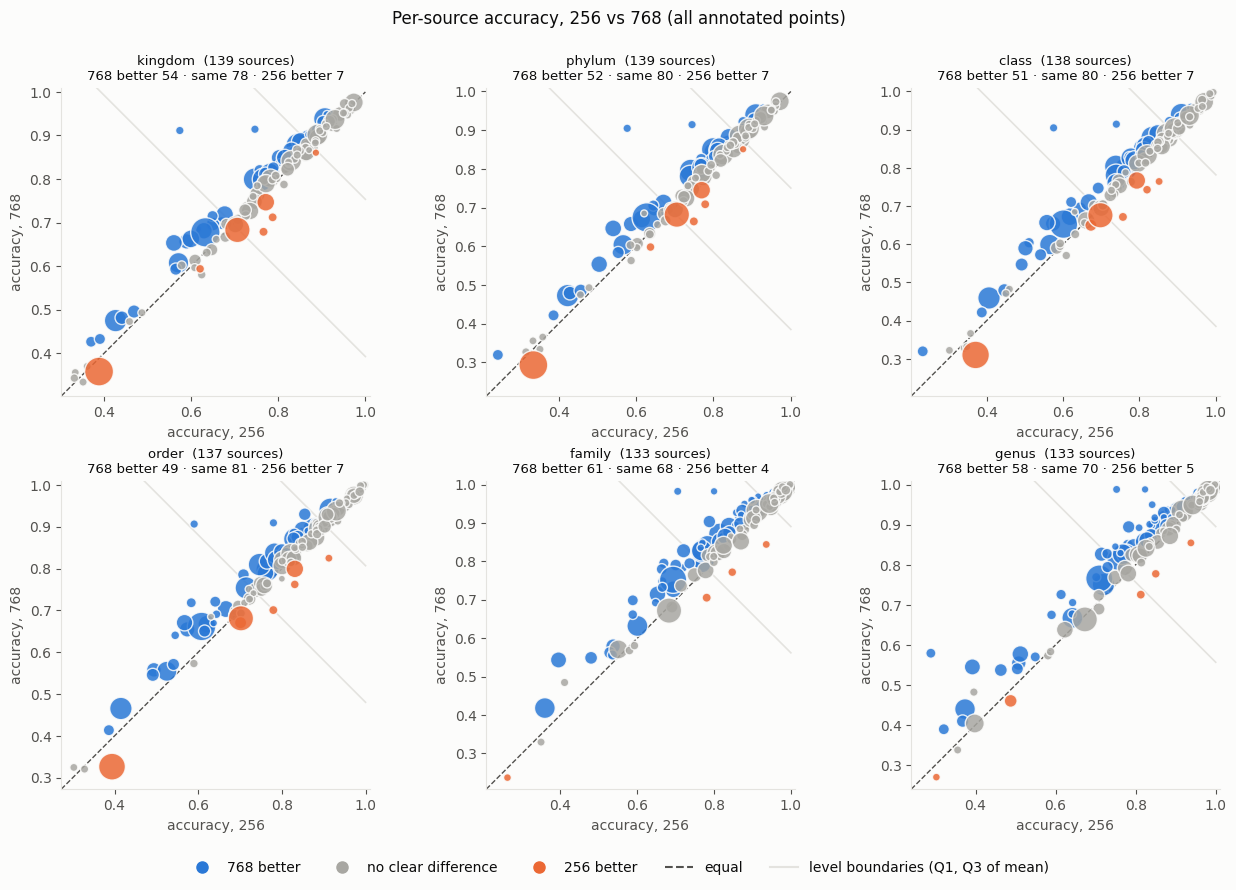

In [6]:
plot_pairs(T, "Per-source accuracy, 256 vs 768 (all annotated points)"); plt.show()

### Level × difference
How many sources are in each cell, per rank. "Both good / both bad / one better" is read off directly: the
`no clear difference` column split by level.

In [7]:
crosstab(T)

diff                     768 better  no clear difference  256 better
rank    level                                                       
kingdom weak for both            16                   16           3
        middle                   29                   36           4
        strong for both           9                   26           0
phylum  weak for both            16                   17           2
        middle                   27                   37           5
        strong for both           9                   26           0
class   weak for both            16                   16           3
        middle                   27                   37           4
        strong for both           8                   27           0
order   weak for both            18                   13           4
        middle                   27                   37           3
        strong for both           4                   31           0
family  weak for both            22                   10           2
        middle                   36                   27           2
        strong for both           3                   31           0
genus   weak for both            21                   10           3
        middle                   34                   29           2
        strong for both           3                   31           0

## 3. Does the gain depend on how hard the source is?

Δ (with its 95% CI) against the mean accuracy of the two models. A negative slope means 768 helps most where both
models are weak. Note that a selection effect pushes this way too (a source that the 256 model gets wrong by chance
tends to improve), but both models are scored on the same points, so this is milder than usual.

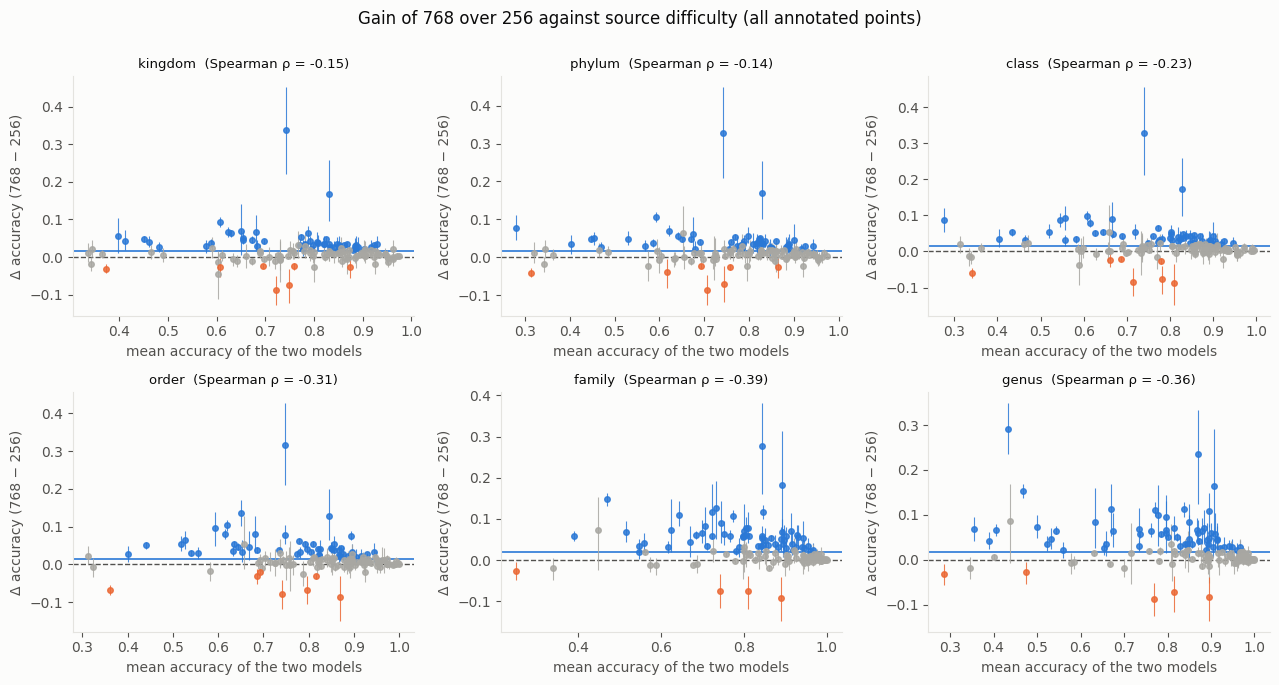

In [8]:
plot_delta_vs_level(T, "Gain of 768 over 256 against source difficulty (all annotated points)"); plt.show()

### Δ per source across ranks
Rows = sources (with ≥ `MIN_N` kingdom points), sorted by kingdom Δ; columns = ranks. Blue = 768 better, orange = 256
better, white = no change; grey = too few points at that rank. Shows whether a source's change is one effect carried
down the hierarchy or rank-specific.

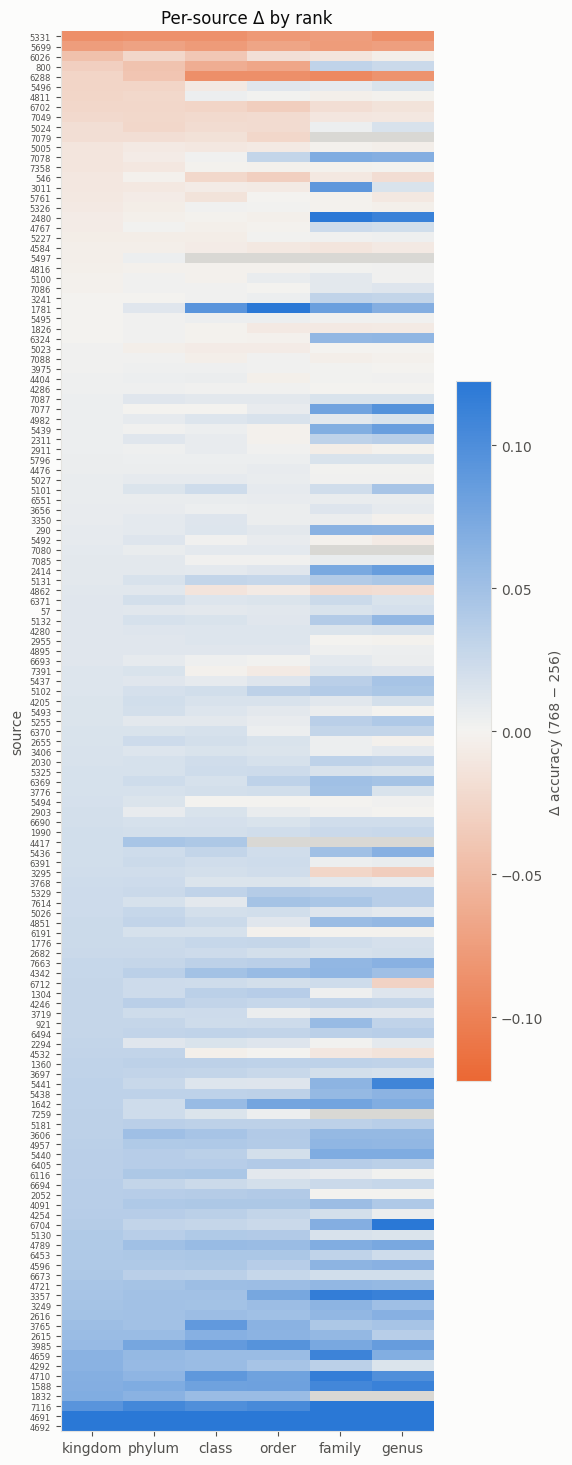

Spearman correlation of per-source Δ between ranks:


,kingdom,phylum,class,order,family,genus
kingdom,1.00,0.97,0.90,0.82,0.55,0.52
phylum,0.97,1.00,0.92,0.85,0.58,0.54
class,0.90,0.92,1.00,0.92,0.64,0.61
order,0.82,0.85,0.92,1.00,0.67,0.64
family,0.55,0.58,0.64,0.67,1.00,0.95
genus,0.52,0.54,0.61,0.64,0.95,1.00


In [9]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
D = pd.DataFrame({r: T[r].delta for r in RANKS}).sort_values("kingdom")
cmap = LinearSegmentedColormap.from_list("div", [C_A, "#f4f3f0", C_B]); cmap.set_bad("#d9d8d4")
lim = np.nanpercentile(np.abs(D.values), 98)
fig, ax = plt.subplots(figsize=(6, 0.12 * len(D) + 1.5))
im = ax.imshow(D.values, aspect="auto", cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim), interpolation="nearest")
ax.set_xticks(range(len(RANKS)), RANKS); ax.set_yticks(range(len(D)), D.index, fontsize=6)
ax.set_ylabel("source"); fig.colorbar(im, ax=ax, label=f"Δ accuracy ({B} − {A})", shrink=0.5)
ax.set_title("Per-source Δ by rank"); plt.show()
print("Spearman correlation of per-source Δ between ranks:")
D.corr(method="spearman").round(2)

## 4. What do the sources that change have in common?

Per source: image size (median megapixels and aspect ratio of the stored images), images, points per image, and
whether the source was in the 256 model's weak quarter. 768 sees 9× the pixels, so the natural hypothesis is that it
gains most on large, detailed images, and loses where images are already small (upsampling) or very elongated.

Spearman ρ between per-source Δ and source properties:


,mpix,aspect,pts_per_img,images,acc_256
kingdom,0.16,-0.13,0.10,0.26,-0.22
phylum,0.17,-0.15,0.08,0.24,-0.22
class,0.22,-0.17,0.06,0.28,-0.31
order,0.17,-0.09,-0.02,0.26,-0.40
family,0.08,0.08,-0.01,0.08,-0.49
genus,0.03,0.13,-0.07,0.05,-0.47


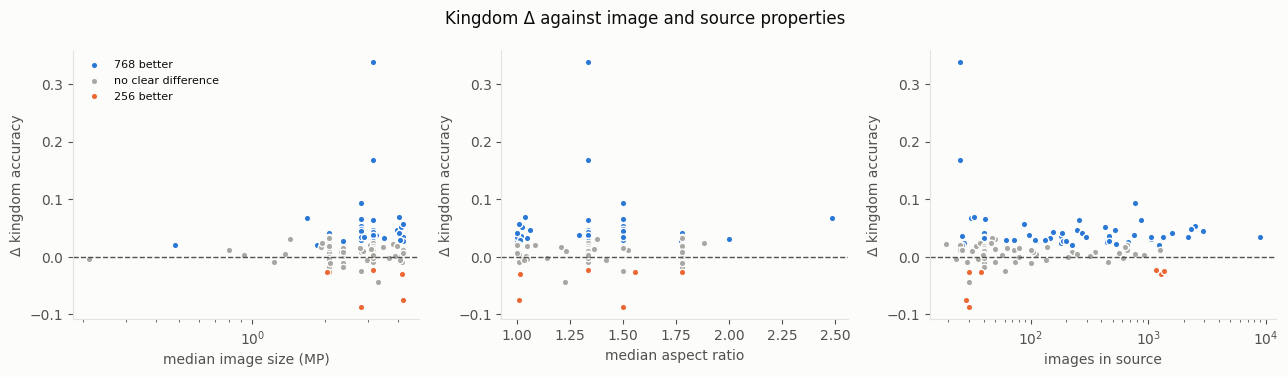

Kingdom Δ by image-size quintile (MP):


,sources,median_delta,mean_delta,n_768_better,n_256_better
mpix,,,,,
"(0.21, 2.074]",38,0.011,0.011,8,2
"(2.074, 2.796]",22,0.012,0.014,9,1
"(2.796, 3.146]",53,0.023,0.029,26,2
"(3.146, 4.194]",26,0.019,0.015,11,2


In [10]:
imgs = pd.read_parquet(DUMPS[A] / "images.parquet")
imgs["mpix"] = imgs.H * imgs.W / 1e6; imgs["aspect"] = np.maximum(imgs.H, imgs.W) / np.minimum(imgs.H, imgs.W)
S = imgs.groupby("source_id").agg(mpix=("mpix", "median"), aspect=("aspect", "median"), pts_per_img=("n_points", "median"))
K = T["kingdom"].join(S)
K["weak_256"] = K.index.isin(WEAK_SOURCES_256)
corr = pd.DataFrame({r: {c: spearmanr(T[r].join(S)[c], T[r].delta, nan_policy="omit").statistic
                         for c in ["mpix", "aspect", "pts_per_img", "images", f"acc_{A}"]} for r in RANKS}).T
print("Spearman ρ between per-source Δ and source properties:")
display(corr.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (c, lab, logx) in zip(axes, [("mpix", "median image size (MP)", True), ("aspect", "median aspect ratio", False),
                                     ("images", "images in source", True)]):
    ax.axhline(0, color=INK2, lw=1, ls="--")
    for cat, col in DIFF_COLOR.items():
        x = K[K["diff"] == cat]
        ax.scatter(x[c], x.delta, s=22, color=col, edgecolor=SURFACE, linewidth=1, label=cat)
    if logx: ax.set_xscale("log")
    ax.set_xlabel(lab); ax.set_ylabel("Δ kingdom accuracy")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Kingdom Δ against image and source properties"); fig.tight_layout(); plt.show()

print("Kingdom Δ by image-size quintile (MP):")
K.groupby(pd.qcut(K.mpix, 5, duplicates="drop"), observed=True).agg(
    sources=("delta", "size"), median_delta=("delta", "median"), mean_delta=("delta", "mean"),
    n_768_better=("diff", lambda s: (s == f"{B} better").sum()), n_256_better=("diff", lambda s: (s == f"{A} better").sum())).round(3)

### The sources that change most, and those weak for both

In [11]:
def source_rows(t: pd.DataFrame, extra: pd.DataFrame = S) -> pd.DataFrame:
    cols = ["n", "images", f"acc_{A}", f"acc_{B}", "delta", "lo", "hi", "level", "diff"]
    return t[cols].join(extra).assign(weak_256=lambda x: x.index.isin(WEAK_SOURCES_256))

kt = source_rows(T["kingdom"])
print(f"Largest {B} gains (kingdom):"); display(kt.sort_values("delta", ascending=False).head(12).round(3))
print(f"Largest {A} advantages (kingdom):"); display(kt.sort_values("delta").head(12).round(3))
print("Weak for both, no clear difference (kingdom):")
display(kt[(kt.level == "weak for both") & (kt["diff"] == "no clear difference")].sort_values(f"acc_{A}").round(3))

# Consistency across ranks: per source, number of ranks where each model is better.
cat = pd.DataFrame({r: T[r]["diff"] for r in RANKS})
cons = pd.DataFrame({f"ranks {B} better": (cat == f"{B} better").sum(1), f"ranks {A} better": (cat == f"{A} better").sum(1),
                     "ranks compared": cat.notna().sum(1)})
print("Sources by how many ranks each model wins (rows: ranks 768 better, cols: ranks 256 better):")
pd.crosstab(cons[f"ranks {B} better"], cons[f"ranks {A} better"])

Largest 768 gains (kingdom):


,n,images,acc_256,acc_768,delta,lo,hi,level,diff,mpix,aspect,pts_per_img,weak_256
source_id,,,,,,,,,,,,,
4692,598,25,0.574,0.911,0.338,0.220,0.451,middle,768 better,3.146,1.333,25.0,True
4691,595,25,0.746,0.914,0.168,0.095,0.258,middle,768 better,3.146,1.333,25.0,False
7116,13791,770,0.560,0.653,0.093,0.080,0.107,weak for both,768 better,2.796,1.500,17.0,True
1832,203,33,0.616,0.685,0.069,0.006,0.140,weak for both,768 better,4.028,1.038,25.0,True
1588,9263,31,0.589,0.657,0.068,0.053,0.081,weak for both,768 better,1.688,2.485,400.0,True
4710,2258,41,0.649,0.715,0.066,0.019,0.111,weak for both,768 better,2.796,1.500,70.0,True
4292,17274,863,0.599,0.662,0.063,0.053,0.073,weak for both,768 better,3.146,1.333,25.0,True
4659,2416,256,0.757,0.820,0.063,0.043,0.083,middle,768 better,3.146,1.333,10.0,False
3985,2148,88,0.370,0.426,0.056,0.011,0.103,weak for both,768 better,4.163,1.007,30.0,True


Largest 256 advantages (kingdom):


,n,images,acc_256,acc_768,delta,lo,hi,level,diff,mpix,aspect,pts_per_img,weak_256
source_id,,,,,,,,,,,,,
5331,893,30,0.766,0.679,-0.087,-0.127,-0.049,middle,256 better,2.796,1.500,30.0,False
5699,840,28,0.787,0.712,-0.075,-0.121,-0.032,middle,256 better,4.161,1.008,30.0,False
6026,662,30,0.624,0.580,-0.044,-0.112,0.011,weak for both,no clear difference,3.303,1.224,30.0,True
800,124547,1273,0.388,0.357,-0.031,-0.041,-0.019,weak for both,256 better,4.135,1.014,100.0,True
6288,711,30,0.620,0.594,-0.027,-0.052,-0.003,weak for both,256 better,2.034,1.556,30.0,True
5496,308,38,0.886,0.860,-0.026,-0.054,-0.003,middle,256 better,2.074,1.778,13.0,False
4811,743,61,0.813,0.787,-0.026,-0.065,0.015,middle,no clear difference,2.796,1.500,25.0,False
6702,17087,1363,0.771,0.747,-0.024,-0.033,-0.016,middle,256 better,3.146,1.333,13.0,False
7049,74319,1168,0.706,0.683,-0.023,-0.028,-0.018,weak for both,256 better,3.146,1.333,64.0,False


Weak for both, no clear difference (kingdom):


,n,images,acc_256,acc_768,delta,lo,hi,level,diff,mpix,aspect,pts_per_img,weak_256
source_id,,,,,,,,,,,,,
4862,625,25,0.331,0.342,0.011,-0.013,0.038,weak for both,no clear difference,3.146,1.333,25.0,True
3295,456,19,0.333,0.355,0.022,0.000,0.046,weak for both,no clear difference,3.802,1.002,25.0,True
7079,501,40,0.351,0.333,-0.018,-0.038,0.000,weak for both,no clear difference,2.357,1.779,13.0,True
7080,463,40,0.361,0.369,0.009,-0.002,0.020,weak for both,no clear difference,2.357,1.779,13.0,True
5102,489,40,0.458,0.472,0.014,-0.004,0.033,weak for both,no clear difference,2.074,1.778,13.0,True
5101,483,40,0.487,0.493,0.006,-0.012,0.025,weak for both,no clear difference,2.074,1.778,13.0,True
7614,808,46,0.578,0.601,0.024,-0.002,0.053,weak for both,no clear difference,1.945,1.880,30.0,True
7078,515,40,0.608,0.596,-0.012,-0.043,0.018,weak for both,no clear difference,2.357,1.779,13.0,True
2911,3850,770,0.609,0.613,0.004,-0.011,0.020,weak for both,no clear difference,0.922,1.778,10.0,True


Sources by how many ranks each model wins (rows: ranks 768 better, cols: ranks 256 better):


ranks 256 better,0,1,2,4,6
ranks 768 better,,,,,
0,51,0,3,2,3
1,5,0,0,0,0
2,17,0,0,1,0
3,7,1,0,0,0
4,14,0,0,0,0
5,6,0,0,0,0
6,29,0,0,0,0


## 5. Live hard coral: per-rank accuracy on live hard coral points

Ground truth restricted to live hard coral (`live` = True, order Scleractinia). Kingdom accuracy here = share predicted
animalia, order = share predicted Scleractinia, and so on; genus is scored only where the annotation gives a genus.
Sources need ≥ `MIN_N_LIVE` live hard coral points labelled at the rank.

In [12]:
LHC = df.lhc == 1
TL = {r: paired_table(LHC, r, min_n=MIN_N_LIVE) for r in RANKS}
HL = pd.DataFrame({r: headline(TL[r], pooled_acc(LHC, r)) for r in RANKS}).T
HL.style.format(precision=3, na_rep="–")

,sources,pooled 256,pooled 768,mean 256,mean 768,median 256,median 768,median Δ,IQR Δ,Wilcoxon p,n 768 better,n no clear diff,n 256 better
kingdom,82,0.836,0.892,0.816,0.864,0.861,0.909,0.035,+0.006 … +0.070,0.000,41,39,2
phylum,82,0.821,0.884,0.799,0.854,0.848,0.907,0.037,+0.009 … +0.081,0.000,45,35,2
class,82,0.796,0.866,0.779,0.840,0.822,0.881,0.044,+0.017 … +0.081,0.000,47,34,1
order,82,0.790,0.862,0.773,0.834,0.817,0.876,0.044,+0.011 … +0.083,0.000,48,33,1
family,67,0.639,0.745,0.635,0.746,0.702,0.807,0.102,+0.050 … +0.152,0.000,51,16,0
genus,65,0.590,0.697,0.593,0.707,0.608,0.764,0.099,+0.050 … +0.152,0.000,50,15,0


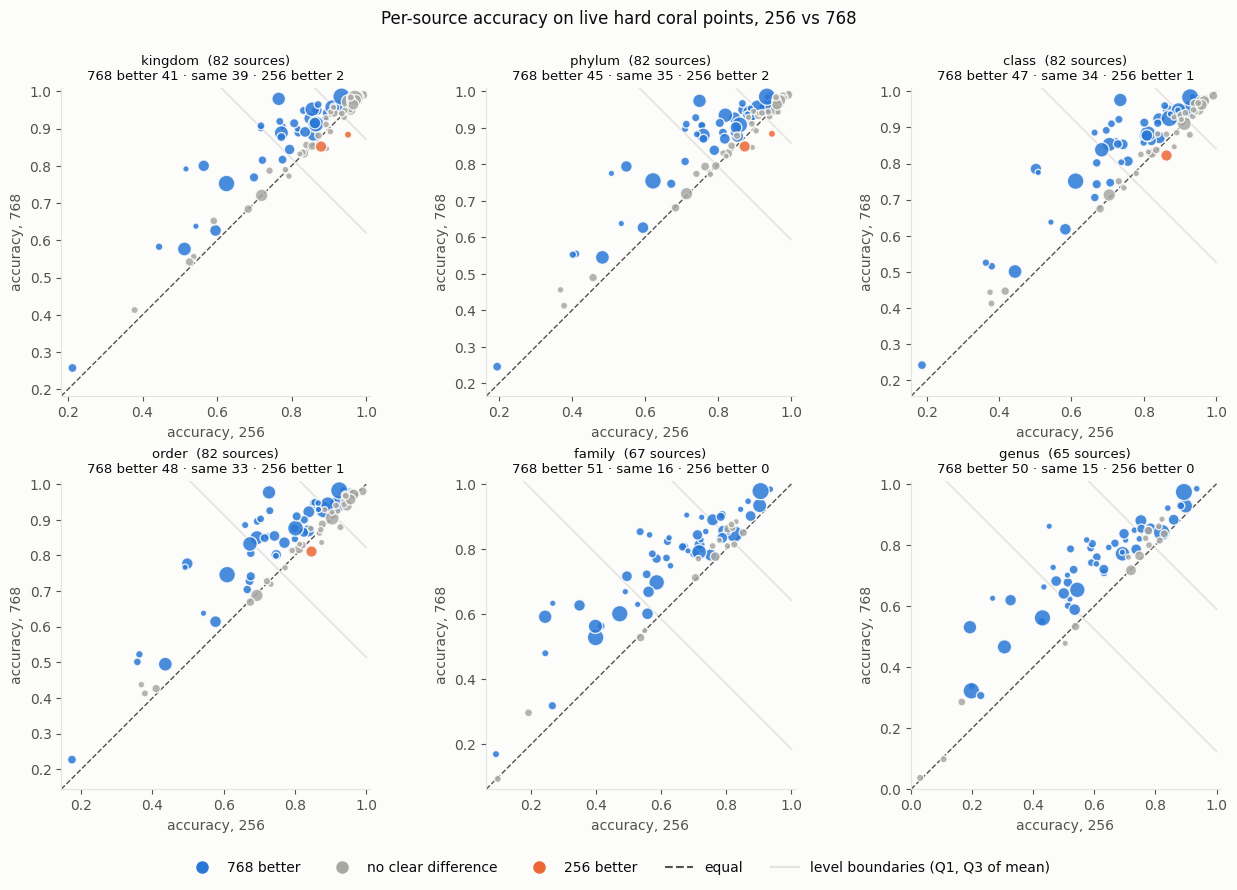

diff                     768 better  no clear difference  256 better
rank    level                                                       
kingdom weak for both            12                    9           0
        middle                   24                   14           2
        strong for both           5                   16           0
phylum  weak for both            11                   10           0
        middle                   26                   12           2
        strong for both           8                   13           0
class   weak for both            14                    7           0
        middle                   25                   14           1
        strong for both           8                   13           0
order   weak for both            14                    7           0
        middle                   26                   13           1
        strong for both           8                   13           0
family  weak for both            13                    4           0
        middle                   26                    7           0
        strong for both          12                    5           0
genus   weak for both            12                    5           0
        middle                   27                    4           0
        strong for both          11                    6           0

/data/vision/beery/scratch/viktordo/mermaid-segmentation/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/data/vision/beery/scratch/viktordo/mermaid-segmentation/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


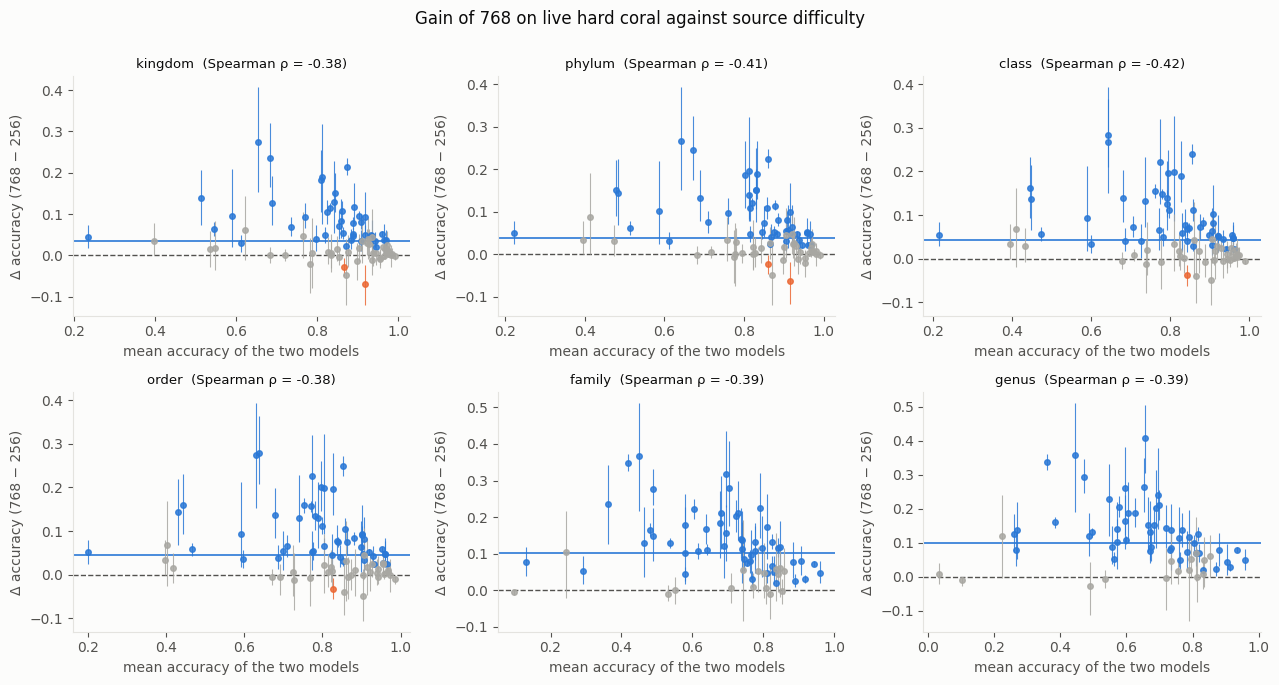

In [13]:
plot_pairs(TL, "Per-source accuracy on live hard coral points, 256 vs 768"); plt.show()
display(crosstab(TL))
plot_delta_vs_level(TL, "Gain of 768 on live hard coral against source difficulty"); plt.show()

### Which raw labels the live-coral errors come from
Per model: the live hard coral labels with the most order-level errors (i.e. not predicted Scleractinia), and what the
order head predicts for them instead.

In [14]:
pred_order = {k: pd.read_parquet(DUMPS[k] / "points.parquet", columns=["pred_order"]).pred_order.astype(str) for k in (A, B)}
x = df.loc[LHC, ["source_label_name", "source_id"]].copy()
for k in (A, B):
    x[f"ok_{k}"] = df.loc[LHC, f"ok_order_{k}"]
    x[f"pred_{k}"] = pred_order[k][LHC]
g = x.groupby("source_label_name", observed=True)
lab = pd.DataFrame({"points": g.size(), "sources": g.source_id.nunique(),
                    f"order_acc_{A}": g[f"ok_{A}"].mean(), f"order_acc_{B}": g[f"ok_{B}"].mean(),
                    f"errors_{A}": g[f"ok_{A}"].apply(lambda s: (~s).sum()), f"errors_{B}": g[f"ok_{B}"].apply(lambda s: (~s).sum()),
                    f"top_wrong_{A}": x[~x[f"ok_{A}"]].groupby("source_label_name", observed=True)[f"pred_{A}"].agg(lambda s: s.mode().iloc[0]),
                    f"top_wrong_{B}": x[~x[f"ok_{B}"]].groupby("source_label_name", observed=True)[f"pred_{B}"].agg(lambda s: s.mode().iloc[0])})
lab.sort_values(f"errors_{A}", ascending=False).head(20).round(3)

,points,sources,order_acc_256,order_acc_768,errors_256,errors_768,top_wrong_256,top_wrong_768
source_label_name,,,,,,,,
hard coral,11154,18,0.512,0.572,5438,4772,none,none
hard coral (massive),9096,10,0.770,0.870,2088,1182,none,none
cred-porites spp_encrusting,3462,2,0.492,0.715,1757,986,none,none
porites,13789,15,0.880,0.929,1649,978,none,none
hard coral (encrusting),3600,10,0.584,0.656,1497,1240,none,none
cred-acropora spp_tabulate,6753,2,0.814,0.833,1258,1127,none,none
acropora cervicornis,15322,11,0.919,0.980,1239,305,none,none
porites lobata,2954,8,0.627,0.667,1103,984,none,none
cred-porites spp_branching,1552,2,0.301,0.572,1085,664,none,none


## 6. Live hard coral detection on all points

Binary task on every point with determinable ground truth: is it live hard coral? Predicted positive = order head
says Scleractinia and p(`live`) > `LIVE_THR`. Unlike section 5, this also counts false alarms (dead coral, rock,
algae predicted as live coral). Per source: precision, recall and F1, each with an image-bootstrap CI for Δ. Sources need
≥ `MIN_N_LIVE` live hard coral points (so recall and F1 are meaningful).

In [15]:
def detection_table(min_pos: int = MIN_N_LIVE, seed: int = SEED) -> dict[str, pd.DataFrame]:
    m = df.lhc.notna()
    x = df.loc[m, ["source_id", "image_id"]].copy()
    y = df.loc[m, "lhc"].to_numpy() == 1
    for k in (A, B):
        p = df.loc[m, f"lhc_pred_{k}"].to_numpy()
        x[f"tp_{k}"], x[f"fp_{k}"], x[f"fn_{k}"] = y & p, ~y & p, y & ~p
    cols = [c for c in x.columns if c[:3] in ("tp_", "fp_", "fn_")]
    ic = x.groupby(["source_id", "image_id"], observed=True)[cols].sum().reset_index()
    stats = {"precision": lambda tp, fp, fn: tp / (tp + fp), "recall": lambda tp, fp, fn: tp / (tp + fn),
             "f1": lambda tp, fp, fn: 2 * tp / (2 * tp + fp + fn)}
    rng = np.random.default_rng(seed)
    rows = {s: [] for s in stats}
    for s, g in ic.groupby("source_id"):
        if (g[f"tp_{A}"] + g[f"fn_{A}"]).sum() < min_pos:
            continue
        W = rng.multinomial(len(g), np.full(len(g), 1 / len(g)), size=N_BOOT).astype(float)
        v = {c: g[c].to_numpy(float) for c in cols}
        with np.errstate(invalid="ignore", divide="ignore"):
            for name, f in stats.items():
                pa = f(*(v[f"{q}_{A}"].sum() for q in ("tp", "fp", "fn")))
                pb = f(*(v[f"{q}_{B}"].sum() for q in ("tp", "fp", "fn")))
                d = f(*(W @ v[f"{q}_{B}"] for q in ("tp", "fp", "fn"))) - f(*(W @ v[f"{q}_{A}"] for q in ("tp", "fp", "fn")))
                lo, hi = np.nanpercentile(d, [2.5, 97.5])
                rows[name].append({"source_id": s, "n": int((g[f"tp_{A}"] + g[f"fn_{A}"]).sum()), "images": len(g),
                                   f"acc_{A}": pa, f"acc_{B}": pb, "lo": lo, "hi": hi})
    return {name: classify(pd.DataFrame(r).set_index("source_id").dropna(subset=[f"acc_{A}", f"acc_{B}"])) for name, r in rows.items()}

TD = detection_table()
m = df.lhc.notna(); y = df.lhc[m] == 1
pooled_det = {}
for k in (A, B):
    p = df.loc[m, f"lhc_pred_{k}"]; tp, fp, fn = (y & p).sum(), (~y & p).sum(), (y & ~p).sum()
    pooled_det[k] = {"precision": tp / (tp + fp), "recall": tp / (tp + fn), "f1": 2 * tp / (2 * tp + fp + fn)}
HD = pd.DataFrame({s: headline(TD[s], (pooled_det[A][s], pooled_det[B][s])) for s in TD}).T
HD.style.format(precision=3, na_rep="–")

,sources,pooled 256,pooled 768,mean 256,mean 768,median 256,median 768,median Δ,IQR Δ,Wilcoxon p,n 768 better,n no clear diff,n 256 better
precision,82,0.672,0.756,0.799,0.838,0.860,0.890,0.036,+0.011 … +0.059,0.000,41,37,4
recall,82,0.754,0.840,0.739,0.811,0.785,0.844,0.048,+0.022 … +0.102,0.000,52,30,0
f1,82,0.710,0.796,0.749,0.810,0.785,0.855,0.047,+0.021 … +0.085,0.000,53,28,1


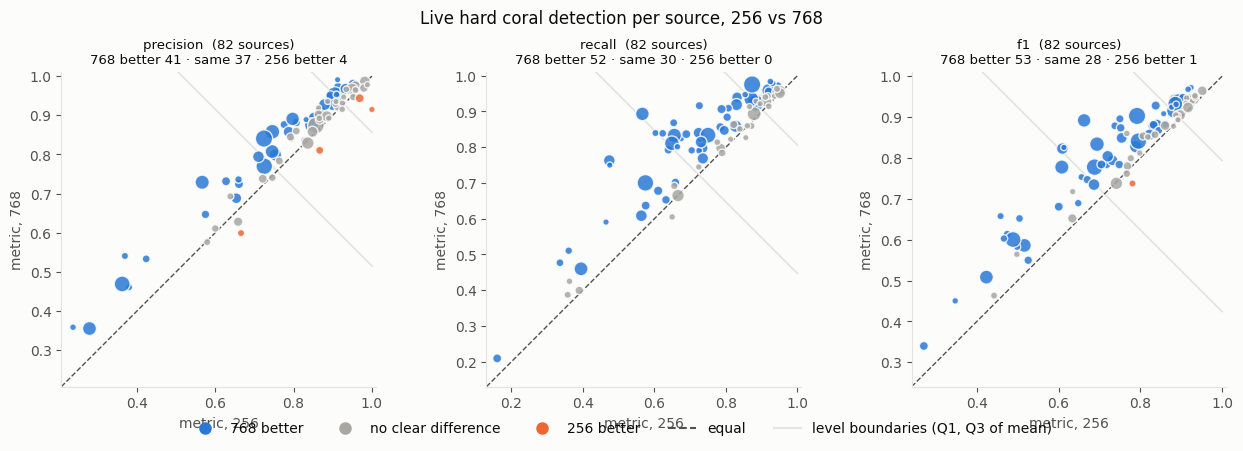

diff                       768 better  no clear difference  256 better
rank      level                                                       
precision weak for both            14                    6           1
          middle                   19                   20           1
          strong for both           8                   11           2
recall    weak for both            15                    6           0
          middle                   28                   12           0
          strong for both           9                   12           0
f1        weak for both            17                    4           0
          middle                   25                   14           1
          strong for both          11                   10           0

In [16]:
plot_pairs(TD, "Live hard coral detection per source, 256 vs 768", label="metric"); plt.show()
display(crosstab(TD))

### Does 768 help more on coral than overall?
Per source: Δ in overall kingdom/genus accuracy (section 2) against Δ in live-coral detection F1 and in genus accuracy
on live hard coral points.

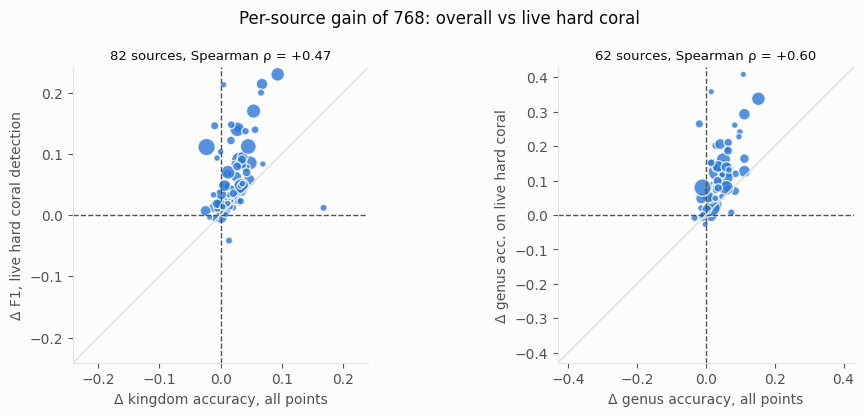

In [17]:
pairs = [("kingdom", T["kingdom"], "F1, live hard coral detection", TD["f1"]),
         ("genus", T["genus"], "genus acc. on live hard coral", TL["genus"])]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (n1, t1, n2, t2) in zip(axes, pairs):
    j = t1[["delta"]].join(t2[["delta", "n"]], rsuffix="_live", how="inner")
    ax.axhline(0, color=INK2, lw=1, ls="--"); ax.axvline(0, color=INK2, lw=1, ls="--")
    lim = np.nanmax(np.abs(j[["delta", "delta_live"]].values)) * 1.05
    ax.plot([-lim, lim], [-lim, lim], color=GRID, lw=1.2)
    ax.scatter(j.delta, j.delta_live, s=8 + 1.2 * np.sqrt(j.n), color=C_B, alpha=0.8, edgecolor=SURFACE, linewidth=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel(f"Δ {n1} accuracy, all points"); ax.set_ylabel(f"Δ {n2}")
    ax.set_title(f"{len(j)} sources, Spearman ρ = {spearmanr(j.delta, j.delta_live).statistic:+.2f}", fontsize=9.5)
fig.suptitle(f"Per-source gain of {B}: overall vs live hard coral"); fig.tight_layout(); plt.show()

### Per-source table
All per-source numbers: overall accuracy per rank, live-hard-coral accuracy per rank, detection P/R/F1.

In [18]:
def wide(tables: dict, prefix: str) -> pd.DataFrame:
    return pd.concat({f"{prefix}{k}": t[[f"acc_{A}", f"acc_{B}", "delta", "diff"]] for k, t in tables.items()}, axis=1)
PER_SOURCE = pd.concat([wide(T, ""), wide(TL, "live_"), wide(TD, "det_")], axis=1).join(
    pd.concat({"source": S.assign(weak_256=S.index.isin(WEAK_SOURCES_256))}, axis=1))
out = REPO / "results_tmp/model_comparison_256_vs_768"; out.mkdir(parents=True, exist_ok=True)
PER_SOURCE.to_csv(out / "per_source.csv")
print("written", out / "per_source.csv")
PER_SOURCE.round(3).head(10)

written /data/vision/beery/scratch/viktordo/mermaid-segmentation/results_tmp/model_comparison_256_vs_768/per_source.csv


kingdom                                      phylum                                       class                                       order                                      family  \
          acc_256 acc_768  delta                 diff acc_256 acc_768  delta                 diff acc_256 acc_768  delta                 diff acc_256 acc_768  delta                 diff acc_256   
source_id                                                                                                                                                                                           
57          0.752   0.764  0.012  no clear difference   0.752   0.763  0.011  no clear difference   0.735   0.746  0.010  no clear difference   0.737   0.748  0.011  no clear difference   0.749   
290         0.816   0.824  0.008  no clear difference   0.819   0.828  0.009  no clear difference   0.812   0.826  0.013  no clear difference   0.818   0.829  0.010  no clear difference   0.719   
546         0.647   0.637 -0.010  no clear difference   0.635   0.633 -0.002  no clear difference   0.673   0.650 -0.023           256 better   0.701   0.670 -0.031           256 better   0.690   
800         0.388   0.357 -0.031           256 better   0.334   0.293 -0.042           256 better   0.371   0.310 -0.061           256 better   0.394   0.326 -0.068           256 better   0.600   
921         0.869   0.898  0.028           768 better   0.868   0.897  0.028           768 better   0.856   0.878  0.022  no clear difference   0.856   0.879  0.024           768 better   0.815   
1304        0.838   0.866  0.028           768 better   0.836   0.860  0.024           768 better   0.839   0.872  0.034           768 better   0.849   0.886  0.037           768 better   0.880   
1360        0.766   0.798  0.031           768 better   0.766   0.798  0.033           768 better   0.765   0.798  0.033           768 better   0.765   0.797  0.032           768 better   0.772   
1588        0.589   0.657  0.068           768 better   0.587   0.657  0.070           768 better   0.574   0.654  0.080           768 better   0.574   0.655  0.081           768 better   0.721   
1642        0.755   0.787  0.032           768 better   0.744   0.767  0.023           768 better   0.692   0.747  0.055           768 better   0.708   0.786  0.077           768 better   0.765   
1776        0.766   0.790  0.025           768 better   0.764   0.789  0.024           768 better   0.758   0.785  0.027           768 better   0.761   0.789  0.028           768 better   0.770   

                                               ... live_genus                            det_precision                                     det_recall                             det_f1          \
          acc_768  delta                 diff  ...    acc_256 acc_768  delta        diff       acc_256 acc_768  delta                 diff    acc_256 acc_768  delta        diff acc_256 acc_768   
source_id                                      ...                                                                                                                                                 
57          0.765  0.016  no clear difference  ...      0.608   0.760  0.152  768 better         0.661   0.724  0.063           768 better      0.784   0.856  0.072  768 better   0.717   0.785   
290         0.783  0.064           768 better  ...      0.631   0.709  0.078  768 better         0.828   0.835  0.006  no clear difference      0.894   0.937  0.042  768 better   0.860   0.883   
546         0.681 -0.009  no clear difference  ...      0.522   0.787  0.265  768 better         0.776   0.876  0.100           768 better      0.726   0.916  0.190  768 better   0.750   0.896   
800         0.632  0.031           768 better  ...        NaN     NaN    NaN         NaN           NaN     NaN    NaN                  NaN        NaN     NaN    NaN         NaN     NaN     NaN   
921         0.870  0.055           768 better  ...      0.199   0.337  0.138

### Interpretation (cbm_final_res256 step 300k vs cbm_final_res768 step 50k, all 144 test sources)

**Overall: 768 is better, and the gain is broad but uneven.** Pooled accuracy rises by 2–3 points at every rank
(kingdom 0.717 → 0.738, genus 0.776 → 0.804). The per-source mean and median move by about the same amount (median
kingdom 0.789 → 0.822). Per source, the median Δ is +1.3 to +2.1 points and the interquartile range is about +0.2 to
+3–5 points, so most sources move a little in the right direction. Out of about 135 sources per rank:
- **768 clearly better: 49–61 sources.** Here the 95% CI excludes 0 and the gain is at least 2 points.
- **No clear difference: 68–81.**
- **256 clearly better: 4–7.**

So 768 is not slightly better everywhere. It is clearly better in about 40% of sources, indistinguishable in about
55%, and worse in a handful. Across ranks, 29 sources improve at all six ranks, 51 change at none, and only 10 get
worse at any rank.

**Where the gain is:**
- **Strong-for-both sources (top quarter) mostly don't change**, because they are near the ceiling: 26 of 35 at
  kingdom and 31 of 34 at family and genus show no clear difference.
- **Weak-for-both sources (bottom quarter) split about evenly:** 16 improve at kingdom, 16 do not.
- **At family and genus the gain grows as sources get harder** (Spearman ρ of Δ against mean accuracy: −0.15 at
  kingdom, −0.39 at family).
- **The kingdom-to-order changes are one effect:** per-source Δ correlates 0.82–0.97 across those ranks. Family and
  genus move together (0.95) but only loosely with kingdom (about 0.55). Extra resolution helps the fine ranks partly
  independently of the coarse ones.
- **Image properties explain little.** Δ correlates only weakly with image size (ρ about 0.16–0.22) and slightly
  negatively with aspect ratio.

**The largest gains are visual problems that resolution fixes:**
- **4692 / 4691** (0.57 → 0.91, 0.75 → 0.91): rock, rubble and sand that 256 called living are now `none`.
- **1588** (panoramic strips, aspect ratio 2.5): massive *Porites* 0.54 → 0.85.
- **2616:** CCA, shadow and turf all improve.
- **4292:** temperate brown algae and bare rock improve.
- **7116:** *Leptastrea*, *Galaxea* and *Halimeda* improve a lot, but turf drops from 0.43 to 0.18 (now called animalia).

**Weak for both, unchanged: these are not resolution problems.** The list is almost exactly groups A and D of
`Weak_Source_Diagnosis.ipynb`:
- Dead-coral sources: 7077–7080, 5101 and 5102.
- Algae and turf conventions: 4862, 2655, 6026.
- 3295 ("bare substrate" on algae-covered rock) and 546 ("all other").
- 4584 (0.2 MP images) and 7358 (colour cast).

Only concept-table or annotation fixes, or colour and low-resolution augmentation, will move these.

**Where 256 wins, the labels are conventions rather than what is visible.** In every case, 768 predicts what the
point looks like, which the concept table scores as wrong:
- **800 (ARMS plates):** `arms-crep-cca` 0.20 → 0.10, now predicted animalia.
- **7049:** `acropora cervicornis dead` 0.34 → 0.19. Dead coral is labelled animalia, and 768 says `none` more often.
- **5331:** `turf overgrowing recently dead coral`.
- **5699:** `all other` and `on quadrat`.
- **6702:** `coral:rock`.

**Live hard coral is where 768 gains most.** On live hard coral points (82 sources with ≥ 100 points):
- **Accuracy rises at every rank:** pooled kingdom 0.836 → 0.892, order 0.790 → 0.862, family 0.639 → 0.745, genus
  0.590 → 0.697.
- **The median per-source gain is +3.5 points at kingdom and about +10 points at family and genus.**
- **Almost no source gets worse:** 768 is clearly better in 41–51 sources, and 256 in at most 2 (none at family or
  genus).
- **Detection improves on both sides:**

  | | precision | recall | F1 |
  |---|---|---|---|
  | 256 | 0.672 | 0.754 | 0.710 |
  | 768 | 0.756 | 0.840 | 0.796 |

  F1 is clearly better in 53 sources and worse in 1.
- **Per source, the coral gain is larger than the overall gain** (points above the diagonal, ρ 0.47 and 0.60).
- **768 mostly fixes coral missed as `none`.** Order errors fall from 1,239 to 305 for *A. cervicornis* and from 1,008
  to 310 for massive *Porites*, and the remaining errors are still mostly `none`.
- **Generic labels stay hard:** `hard coral` (0.57) and `other hard coral` (0.67) remain the weakest.

**Summary.** 768 helps most on visual detail, especially telling live coral from substrate and naming it to genus.
It makes little difference on sources that are already easy. The sources weak for both models are limited by labelling
conventions and image quality, which resolution does not fix. The few losses come from labels whose ground truth
contradicts appearance.
